Exact ground energy: -3.0
Iteration k=3: bit=0, P(1)=0.0000, feedback=-0.000000
Iteration k=2: bit=1, P(1)=1.0000, feedback=-0.000000
Iteration k=1: bit=1, P(1)=0.8516, feedback=-0.785398
Iteration k=0: bit=0, P(1)=0.3099, feedback=-1.178097
NOISE-FREE GATE-LEVEL IQPE
Bits: [0 1 1 0]
Phase: 0.375
Recovered energy: -3.0
Exact energy: -3.0
Absolute error: 0.0
p= 0.0000 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0010 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0025 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0050 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0100 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0200 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0500 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.1000 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000


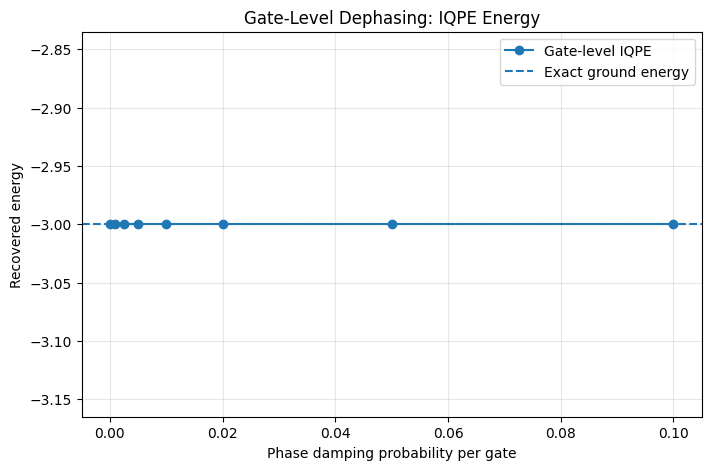

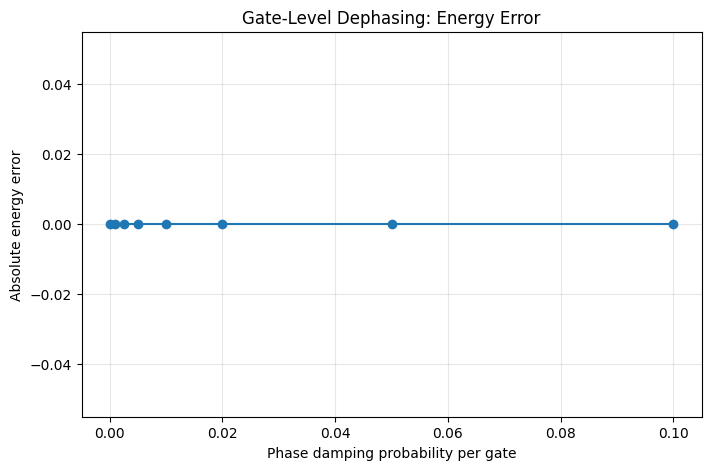

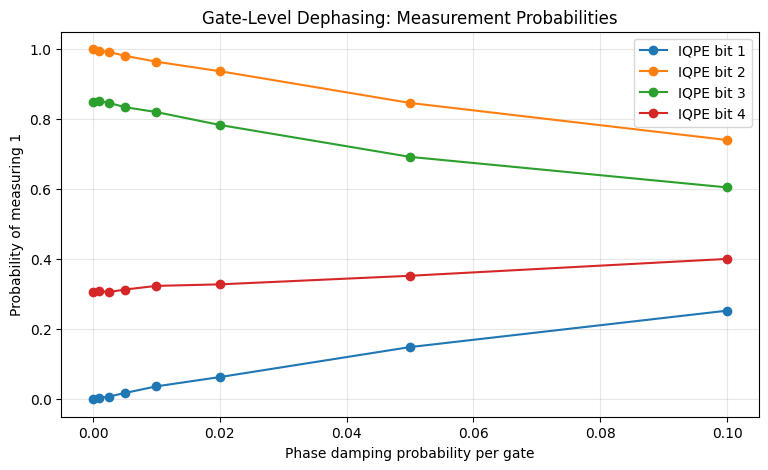

In [3]:
!pip install pennylane scipy matplotlib
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt

# HAMILTONIAN AND EXACT GROUND STATE


J = 1.0
t = np.pi / 4
N_BITS = 4

H = J * (
    qml.PauliX(0) @ qml.PauliX(1)
    + qml.PauliY(0) @ qml.PauliY(1)
    + qml.PauliZ(0) @ qml.PauliZ(1)
)

H_matrix = qml.matrix(H)
eigenvalues, eigenvectors = np.linalg.eigh(H_matrix)

ground_state = eigenvectors[:, 0]
exact_energy = eigenvalues[0]

print("Exact ground energy:", exact_energy)


def noisy_h(wire, p):
    qml.Hadamard(wires=wire)
    if p > 0:
        qml.PhaseDamping(p, wires=wire)


def noisy_s(wire, p):
    qml.PhaseShift(np.pi / 2, wires=wire)
    if p > 0:
        qml.PhaseDamping(p, wires=wire)


def noisy_sdg(wire, p):
    qml.PhaseShift(-np.pi / 2, wires=wire)
    if p > 0:
        qml.PhaseDamping(p, wires=wire)


def noisy_rz(angle, wire, p):
    qml.RZ(angle, wires=wire)
    if p > 0:
        qml.PhaseDamping(p, wires=wire)


def noisy_cnot(control, target, p):
    qml.CNOT(wires=[control, target])

    # Independent phase damping on both qubits
    # after the two-qubit CNOT gate.
    if p > 0:
        qml.PhaseDamping(p, wires=control)
        qml.PhaseDamping(p, wires=target)



# CONTROLLED PAULI ROTATIONS

# Implements:
# Controlled exp(-i * theta * P)
#
# P can be XX, YY or ZZ.
#
# Wires:
# ancilla = 0
# system  = 1, 2


def controlled_pauli_rotation(pauli, theta, p):

    # Change the Pauli basis to Z


    if pauli == "XX":

        noisy_h(1, p)
        noisy_h(2, p)

    elif pauli == "YY":

        # H S† maps Y to Z
        noisy_sdg(1, p)
        noisy_h(1, p)

        noisy_sdg(2, p)
        noisy_h(2, p)

    elif pauli == "ZZ":
        pass

    else:
        raise ValueError("Pauli term must be XX, YY or ZZ")


    noisy_cnot(1, 2, p)


    noisy_rz(theta, 2, p)
    noisy_cnot(0, 2, p)

    noisy_rz(-theta, 2, p)
    noisy_cnot(0, 2, p)


    noisy_cnot(1, 2, p)


    if pauli == "XX":

        noisy_h(1, p)
        noisy_h(2, p)

    elif pauli == "YY":

        noisy_h(1, p)
        noisy_s(1, p)

        noisy_h(2, p)
        noisy_s(2, p)

def controlled_heisenberg_evolution(theta, p):

    # Since XX, YY and ZZ commute:
    # exp[-i theta(XX + YY + ZZ)]
    # = exp(-i theta XX)
    #   exp(-i theta YY)
    #   exp(-i theta ZZ)

    controlled_pauli_rotation("XX", theta, p)
    controlled_pauli_rotation("YY", theta, p)
    controlled_pauli_rotation("ZZ", theta, p)



def gate_level_iqpe_step(
    theta,
    feedback,
    p_dephase=0.0,
    shots=5000
):

    dev = qml.device(
        "default.mixed",
        wires=3,
        shots=shots
    )

    @qml.qnode(dev)
    def circuit():

        # Prepare the system ground state.
        # State preparation is kept ideal in this model.
        qml.StatePrep(ground_state, wires=[1, 2])

        # Initial Hadamard on ancilla
        noisy_h(0, p_dephase)

        # Controlled U^(2^k)
        controlled_heisenberg_evolution(
            theta,
            p_dephase
        )

        # Adaptive feedback rotation
        noisy_rz(feedback, 0, p_dephase)

        # Final Hadamard
        noisy_h(0, p_dephase)

        return qml.sample(wires=0)

    samples = np.asarray(circuit()).astype(int)

    probability_one = np.mean(samples)

    # Majority-vote measurement
    bit = int(probability_one > 0.5)

    return bit, probability_one



# GATE-LEVEL IQPE


def run_gate_level_iqpe(
    p_dephase=0.0,
    n_bits=N_BITS,
    shots=5000,
    verbose=False
):

    bits = []
    probabilities = []

    for k in reversed(range(n_bits)):

        theta = J * t * (2 ** k)

        feedback = -np.pi * sum(
            bits[j] / (2 ** (j + 1))
            for j in range(len(bits))
        )

        bit, probability_one = gate_level_iqpe_step(
            theta=theta,
            feedback=feedback,
            p_dephase=p_dephase,
            shots=shots
        )

        bits.append(bit)
        probabilities.append(probability_one)

        if verbose:
            print(
                f"Iteration k={k}: "
                f"bit={bit}, "
                f"P(1)={probability_one:.4f}, "
                f"feedback={feedback:.6f}"
            )

    bits = np.array(bits)

    phase = sum(
        bits[i] / (2 ** (i + 1))
        for i in range(n_bits)
    )

    energy = -(2 * np.pi * phase) / t

    error = abs(energy - exact_energy)

    return {
        "bits": bits,
        "phase": phase,
        "energy": energy,
        "error": error,
        "probabilities": np.array(probabilities)
    }



# NOISE-FREE VALIDATION


ideal_result = run_gate_level_iqpe(
    p_dephase=0.0,
    shots=10000,
    verbose=True
)

print("NOISE-FREE GATE-LEVEL IQPE")

print("Bits:", ideal_result["bits"])
print("Phase:", ideal_result["phase"])
print("Recovered energy:", ideal_result["energy"])
print("Exact energy:", exact_energy)
print("Absolute error:", ideal_result["error"])

dephasing_levels = [
    0.0,
    0.001,
    0.0025,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10
]

shots = 10000

energies = []
errors = []
phases = []
all_bits = []
all_probabilities = []

for p in dephasing_levels:

    result = run_gate_level_iqpe(
        p_dephase=p,
        shots=shots
    )

    energies.append(result["energy"])
    errors.append(result["error"])
    phases.append(result["phase"])
    all_bits.append(result["bits"])
    all_probabilities.append(result["probabilities"])

    print(
        f"p={p:7.4f} | "
        f"bits={result['bits']} | "
        f"phase={result['phase']:.5f} | "
        f"energy={result['energy']:.5f} | "
        f"error={result['error']:.5f}"
    )




plt.figure(figsize=(8, 5))

plt.plot(
    dephasing_levels,
    energies,
    marker="o",
    label="Gate-level IQPE"
)

plt.axhline(
    exact_energy,
    linestyle="--",
    label="Exact ground energy"
)

plt.xlabel("Phase damping probability per gate")
plt.ylabel("Recovered energy")
plt.title("Gate-Level Dephasing: IQPE Energy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



# PLOT: ABSOLUTE ENERGY ERROR


plt.figure(figsize=(8, 5))

plt.plot(
    dephasing_levels,
    errors,
    marker="o"
)

plt.xlabel("Phase damping probability per gate")
plt.ylabel("Absolute energy error")
plt.title("Gate-Level Dephasing: Energy Error")
plt.grid(alpha=0.3)
plt.show()


# PLOT: P(1) FOR EACH IQPE ITERATION

all_probabilities = np.array(all_probabilities)

plt.figure(figsize=(9, 5))

for i in range(N_BITS):

    plt.plot(
        dephasing_levels,
        all_probabilities[:, i],
        marker="o",
        label=f"IQPE bit {i + 1}"
    )

plt.xlabel("Phase damping probability per gate")
plt.ylabel("Probability of measuring 1")
plt.title("Gate-Level Dephasing: Measurement Probabilities")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


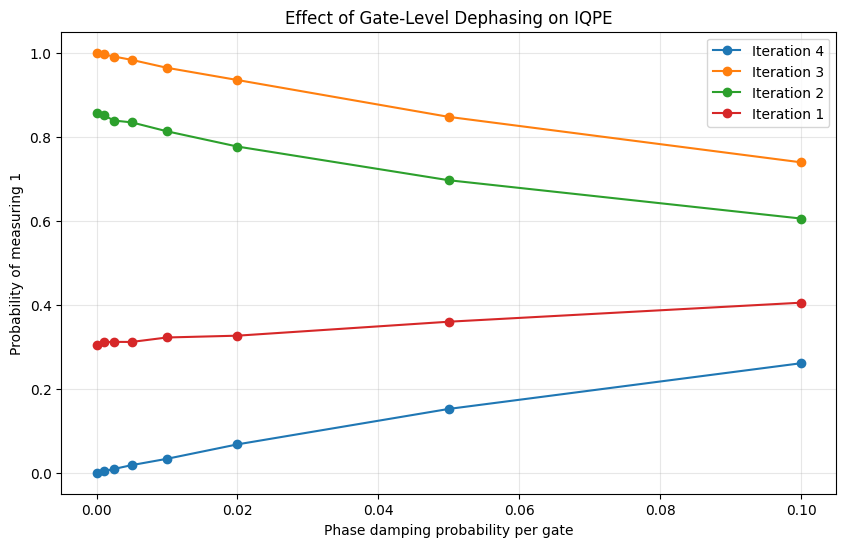


Measurement probabilities:

p=0.0000 | [0.     1.     0.8569 0.305 ]
p=0.0010 | [0.0037  0.99615 0.85115 0.3111 ]
p=0.0025 | [0.009  0.9909 0.8385 0.3115]
p=0.0050 | [0.0181  0.98295 0.83415 0.3114 ]
p=0.0100 | [0.03315 0.9641  0.8129  0.322  ]
p=0.0200 | [0.0675 0.935  0.7766 0.3263]
p=0.0500 | [0.1519  0.84725 0.6964  0.35955]
p=0.1000 | [0.2607  0.73905 0.6052  0.40485]


In [2]:
# DIAGNOSTIC: PROBABILITY OF MEASURING 1

dephasing_levels = [
    0.0, 0.001, 0.0025, 0.005,
    0.01, 0.02, 0.05, 0.10
]

shots = 20000

probability_data = []

for p in dephasing_levels:

    result = run_gate_level_iqpe(
        p_dephase=p,
        shots=shots
    )

    probability_data.append(result["probabilities"])

probability_data = np.array(probability_data)

plt.figure(figsize=(10, 6))

for i in range(N_BITS):

    plt.plot(
        dephasing_levels,
        probability_data[:, i],
        marker="o",
        label=f"Iteration {N_BITS-i}"
    )

plt.xlabel("Phase damping probability per gate")
plt.ylabel("Probability of measuring 1")
plt.title("Effect of Gate-Level Dephasing on IQPE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Print numerical values

print("\nMeasurement probabilities:\n")

for i, p in enumerate(dephasing_levels):

    print(
        f"p={p:.4f} | "
        f"{probability_data[i]}"
    )
